HU5 - CLUSTERING DE MEDICAMENTOS CON K-MEANS

Objetivo: agrupar automáticamente los medicamentos del CSV limpio de la HU4 en perfiles o tipologías, usando el modelo K-Means 


Pasos:
1. Cargar el CSV limpio y preparar las columnas numéricas.
2. Escalar los datos.
3. Elegir el número de clústeres (k).
4. Entrenar el modelo K-Means.
5. Analizar los clústeres y ponerles nombre.
6. Guardar un CSV nuevo con la columna del clúster asignado.

In [14]:
import pandas as pd #sirve para leer el csv y trabajar con la tabla df. 
import numpy as np #librería de cálculo numérico sobre la que funcionan pandas y scikitlearn 
import matplotlib.pyplot as plt #para dibujar gráficos 
import seaborn as sns  #funciona encima de matplotlib y hacer gráficas bonitas con menos código 
import warnings as wr 

wr.filterwarnings("ignore") #para que python no muestre ningun warning 

RANDOM_SEED = 42 #semilla para que los resultados sean reproducibles. 

df = pd.read_csv("medicamentos_epilepsia_HU4_limpio.csv")
print(df.shape) #muestra el tamaño del dataframe 
#df.columns.tolist()
pd.set_option("display.max_columns", None)  # mostrar todas las columnas al ver un DataFrame
df.head() #las 5 primeras dfilas 


(580, 31)


,nombre,pactivos,labtitular,labcomercializador,dosis,dosis_unidad,comercializado,generico,afecta_conduccion,triangulo_negro,num_principios_activos,Volumen Informativo de Seguridad (num palabras),Complejidad del Desglose Clínico (num tablas),Indicador de Riesgo Severo (num veces grave/s),Precio venta al público con IVA,Tratamiento de larga duración,forma_farmaceutica_simplificada_CAPSULA,forma_farmaceutica_simplificada_COMPRIMIDO,forma_farmaceutica_simplificada_COMPRIMIDO LIBERACION MODIFICADA,forma_farmaceutica_simplificada_COMPRIMIDO MASTICABLE,forma_farmaceutica_simplificada_GEL/PASTA/LIQUIDO BUCAL,forma_farmaceutica_simplificada_INYECTABLE,forma_farmaceutica_simplificada_SOLUCION/SUSPENSION GOTAS ORALES,forma_farmaceutica_simplificada_SOLUCIÓN/SUSPENSIÓN ORAL,vias_administracion_VÍA INTRAMUSCULAR,vias_administracion_VÍA ORAL,vias_administracion_Vía bucal (buccal use),Estado_ALTA,Estado_BAJA GENERAL,Estado_BAJA POR NO COMERCIALIZAR,Estado_SUSPENSION TEMPORAL GENERAL
0,CARBAMAZEPINA NORMON 200 mg COMPRIMIDOS EFG,CARBAMAZEPINA,Laboratorios Normon S.A.,Laboratorios Normon S.A.,200.0,mg,1,1,1,0,1,2558,0,16,3.98,1,0,1,0,0,0,0,0,0,0,1,0,1,0,0,0
1,CARBAMAZEPINA NORMON 400 mg COMPRIMIDOS EFG,CARBAMAZEPINA,Laboratorios Normon S.A.,Laboratorios Normon S.A.,400.0,mg,1,1,1,0,1,2558,0,16,7.96,1,0,1,0,0,0,0,0,0,0,1,0,1,0,0,0
2,CRISOMET 100 mg COMPRIMIDOS MASTICABLES/DISPER...,LAMOTRIGINA,Glaxosmithkline S.A.,Glaxosmithkline S.A.,100.0,mg,1,0,1,0,1,2420,8,16,26.35,1,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0
3,CRISOMET 200 mg COMPRIMIDOS MASTICABLES/DISPER...,LAMOTRIGINA,Glaxosmithkline S.A.,Glaxosmithkline S.A.,200.0,mg,1,0,1,0,1,2420,8,16,28.24,1,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0
4,CRISOMET 25 mg COMPRIMIDOS MASTICABLES/DISPERS...,LAMOTRIGINA,Glaxosmithkline S.A.,Glaxosmithkline S.A.,25.0,mg,1,0,1,0,1,2420,8,16,6.59,1,0,0,0,1,0,0,0,0,0,1,0,0,0,1,0


PREPARAMOS LAS COLUMNAS NUMÉRICAS PARA EL MODELO

K-Means agrupa los medicamentos según la distancia entre ellos, así que solo puede trabajar con columnas numéricas.

Creamos una copia `X` solo para el modelo y dejamos `df` intacto, porque al final guardaremos `df` con una columna nueva que indique el clúster de cada medicamento.

Pasos:
- Quitamos las columnas de texto que solo sirven para identificar el medicamento: `nombre`, `pactivos`, `labtitular`, `labcomercializador`, `dosis_unidad`.

- `Tratamiento de larga duración` tiene valores SI/NO, así que la pasamos a 1/0.

- `Estado` tiene 4 categorías (ALTA, BAJA GENERAL, BAJA POR NO COMERCIALIZAR, SUSPENSION TEMPORAL GENERAL) sin un orden entre ellas, así que la pasamos a dummies, igual que hicimos en la HU4 con la forma farmacéutica y la vía de administración.





In [15]:
#quitamos las columnas con texto 
columnas_con_texto = ["nombre","pactivos", "labtitular", "labcomercializador", "dosis_unidad"]
X = df.drop(columns = columnas_con_texto)

ESCALAMOS LOS DATOS

K-Means mide la distancia entre medicamentos. Si no escalamos, las columnas con números grandes dominan la distancia: "Volumen Informativo de Seguridad" va de 219 a 3347, mientras que las columnas binarias solo valen 0 o 1.

Con StandardScaler, cada columna pasa a tener media 0 y desviación típica 1, así que todas pesan lo mismo en el modelo.

In [16]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_escalado = scaler.fit_transform(X) #calculamos la media y desviación típica de cada columna y transforma los datios 


#fit_transform hace dos cosas: 
    #1 primero calcula la media y dtip de cada una de las columnas (fit)
    #2 aplica la formula valor-media)/ desv 

#lo pasamos a DataFrame para poder ver el rsultado 
X_escalado = pd.DataFrame(X_escalado,columns = X.columns)
X_escalado.describe().T[["mean", "std"]]


,mean,std
dosis,-6.125368e-18,1.000863
comercializado,1.470088e-16,1.000863
generico,-7.350442e-17,1.000863
afecta_conduccion,-6.309129e-16,1.000863
triangulo_negro,-2.450147e-17,1.000863
num_principios_activos,-9.142112e-16,1.000863
Volumen Informativo de Seguridad (num palabras),-3.675221e-17,1.000863
Complejidad del Desglose Clínico (num tablas),-3.675221e-17,1.000863
Indicador de Riesgo Severo (num veces grave/s),0.000000e+00,1.000863
Precio venta al público con IVA,-1.592596e-16,1.000863


VEMOS TODAS LAS MEDIAS EN 0 Y LA DESVIACION TIPICA EN 1 

 ELEGIMOS EL NÚMERO DE CLÚSTERES (k)

Probamos K-Means con k de 2 a 10 y usamos este criterio:

- Método del codo (inercia): la inercia mide cómo de compactos son los clústeres (suma de distancias de cada punto a su centro). Siempre baja al aumentar k, así que buscamos el "codo", el punto a partir del cual deja de bajar mucho.


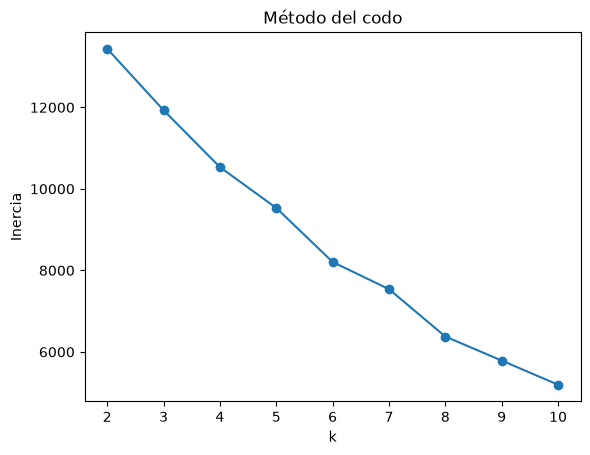

In [17]:
from sklearn.cluster import KMeans

valores_k = range(2, 11)
inercias = []

for k in valores_k:
    kmeans = KMeans(n_clusters=k, random_state=RANDOM_SEED, n_init=10)
    kmeans.fit(X_escalado)
    inercias.append(kmeans.inertia_)

plt.plot(valores_k, inercias, marker="o")
plt.title("Método del codo")
plt.xlabel("k")
plt.ylabel("Inercia")
plt.show()


No se ve un codo claro. Así que elegiremos k = 5 porque da grupos de tamaño razonable y que se puedan interpretar  

In [18]:
kmeans = KMeans(n_clusters=5, random_state= RANDOM_SEED, n_init= 10)
clusters = kmeans.fit_predict(X_escalado)   

pd.Series(clusters).value_counts().sort_index()  #cuántos medicamentos hay en cada clúster
df.loc[clusters == 2, "nombre"]
#df.loc[clusters == 3, "nombre"]

0            CARBAMAZEPINA NORMON 200 mg COMPRIMIDOS EFG
1            CARBAMAZEPINA NORMON 400 mg COMPRIMIDOS EFG
6                              EDEMOX 250 mg COMPRIMIDOS
8           ESLICARBAZEPINA CINFA 800 MG COMPRIMIDOS EFG
9          ESLICARBAZEPINA NORMON 200 MG COMPRIMIDOS EFG
                             ...                        
557    VIMPAT 50 mg COMPRIMIDOS RECUBIERTOS CON PELICULA
558                           ZEBINIX 200 MG COMPRIMIDOS
559                     ZEBINIX 50 MG/ML SUSPENSION ORAL
560                       ZEKILEP 200 MG COMPRIMIDOS EFG
561                       ZEKILEP 800 MG COMPRIMIDOS EFG
Name: nombre, Length: 296, dtype: str

In [19]:
X_con_cluster = X.copy()
X_con_cluster["cluster"] = clusters  #añadimos el clúster de cada medicamento

X_con_cluster.groupby("cluster").mean().round(2).T  #media de cada columna en cada clúster

cluster,0,1,2,3,4
dosis,315.26,148.86,290.04,7.50,108.63
comercializado,0.00,1.00,1.00,1.00,1.00
generico,0.98,0.89,0.82,0.00,0.63
afecta_conduccion,1.00,1.00,0.99,1.00,1.00
triangulo_negro,0.01,0.01,0.02,0.00,0.00
num_principios_activos,1.00,1.01,1.00,1.00,1.00
Volumen Informativo de Seguridad (num palabras),1000.39,1611.37,785.56,314.00,2411.26
Complejidad del Desglose Clínico (num tablas),3.57,3.54,3.60,8.33,8.20
Indicador de Riesgo Severo (num veces grave/s),7.55,8.11,8.32,6.00,15.40
Precio venta al público con IVA,44.82,25.08,61.85,85.35,20.59


In [20]:
df["cluster"] = clusters  #añadimos la columna al df original (es la que guardaremos en el CSV)

for c in sorted(df["cluster"].unique()):
    print(f"Clúster {c} ({(df['cluster'] == c).sum()} medicamentos):")
    print(df[df["cluster"] == c]["pactivos"].value_counts().head(5))
    print()

Clúster 0 (95 medicamentos):
pactivos
LEVETIRACETAM              28
PREGABALINA                28
LACOSAMIDA                 15
GABAPENTINA                 8
ESLICARBAZEPINA ACETATO     5
Name: count, dtype: int64

Clúster 1 (151 medicamentos):
pactivos
PREGABALINA                         91
ZONISAMIDA                          31
GABAPENTINA                         24
VALPROATO SODIO, VALPROICO ACIDO     2
FENITOINA SODICA                     1
Name: count, dtype: int64

Clúster 2 (296 medicamentos):
pactivos
LACOSAMIDA                 72
LEVETIRACETAM              66
BRIVARACETAM               40
ESLICARBAZEPINA ACETATO    25
PERAMPANEL                 19
Name: count, dtype: int64

Clúster 3 (3 medicamentos):
pactivos
MIDAZOLAM HIDROCLORURO    3
Name: count, dtype: int64

Clúster 4 (35 medicamentos):
pactivos
LAMOTRIGINA    35
Name: count, dtype: int64



ANÁLISIS DE LOS CLÚSTERES

- Clúster 0 (116): 68 % tratamiento de larga duración. Entre los grupos grandes, es el de precio medio más bajo (22 €), fichas técnicas más largas (2100 palabras) y más menciones de "grave" (13,3). Es el único grupo con comprimidos masticables (30 %). Principios activos principales: lamotrigina, zonisamida y gabapentina. Nota: 14 medicamentos de este grupo aparecen como comercializados pero con estado "BAJA POR NO COMERCIALIZAR", una contradicción que viene de los datos de origen.
- Clúster 1 (367): todos comercializados y de alta, casi ninguno de larga duración (4 %), fichas más cortas de los grupos grandes (849 palabras), precio medio 55,5 €. Mayoría comprimidos (68 %). Principios activos principales: pregabalina, lacosamida y levetiracetam.
- Clúster 2 (2): ácido valproico de liberación prolongada. Ambos tienen 2 principios activos y triángulo negro, y son los únicos con comprimido de liberación modificada.
- Clúster 3 (3): BUCCOLAM (midazolam). Únicos por vía bucal, ninguno genérico y el precio medio más alto (85 €).
- Clúster 4 (95): ninguno comercializado ni de alta (51 % baja general, 29 % baja por no comercializar, 20 % suspensión temporal).

In [21]:
nombres_clusters = {
    0: "Larga duración, económicos y con más avisos de riesgo",
    1: "Comercializados de uso estándar",
    2: "Especial: valproico de liberación prolongada",
    3: "Especial: midazolam vía bucal",
    4: "No comercializados / dados de baja",
}

df["perfil"] = df["cluster"].map(nombres_clusters)  #mismo map que usamos con SI/NO
df["perfil"].value_counts()

perfil
Especial: valproico de liberación prolongada             296
Comercializados de uso estándar                          151
Larga duración, económicos y con más avisos de riesgo     95
No comercializados / dados de baja                        35
Especial: midazolam vía bucal                              3
Name: count, dtype: int64

 GUARDAMOS EL RESULTADO

Guardamos el CSV limpio de la HU4 con las columnas nuevas:
- `cluster`: número de clúster asignado por K-Means (0 a 4).
- `perfil`: nombre del perfil que le hemos dado a cada clúster.

In [22]:
df.to_csv("medicamentos_epilepsia_HU5_clusters.csv", index=False)

#comprobamos que se ha guardado bien leyéndolo de nuevo
comprobacion = pd.read_csv("medicamentos_epilepsia_HU5_clusters.csv")
print(comprobacion.shape)
comprobacion[["nombre", "cluster", "perfil"]].head()
df.drop(columns=["cluster"]).to_csv("medicamentos_epilepsia_HU5_clusters.csv", index=False)

(580, 33)


# GRÁFICOS 

In [23]:
colores = {0: "#2a78d6", 1: "#eb6834", 2: "#1baf7a", 3: "#eda100", 4: "#e87ba4"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})  #quitamos los bordes de arriba y derecha

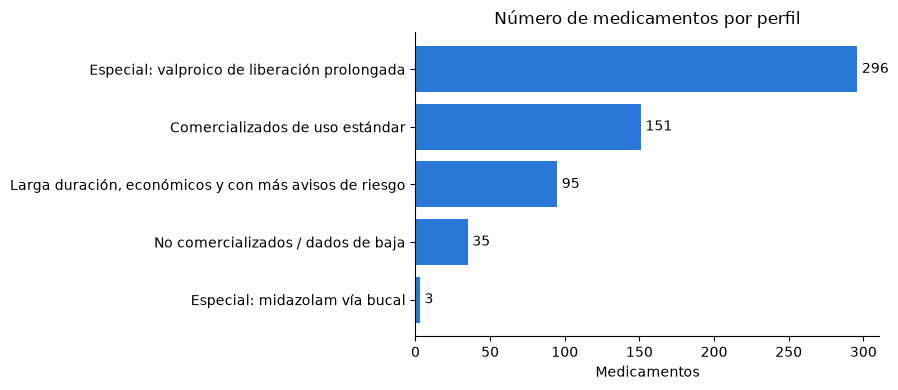

In [24]:
tamanos = df["perfil"].value_counts().sort_values()

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(tamanos.index, tamanos.values, color="#2a78d6")
for i, v in enumerate(tamanos.values):
    ax.text(v + 3, i, str(v), va="center")  #escribe el número al final de cada barra
ax.set_title("Número de medicamentos por perfil")
ax.set_xlabel("Medicamentos")
plt.tight_layout()
plt.show()

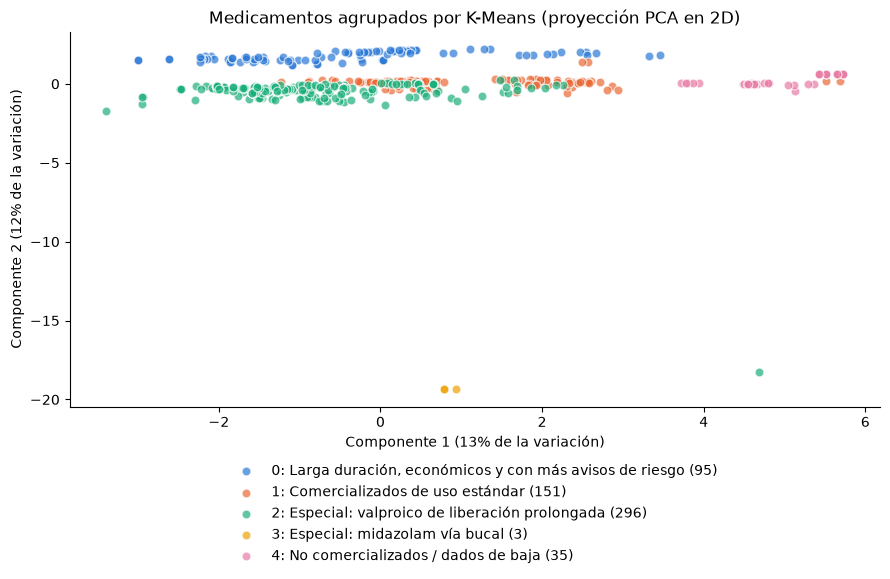

In [25]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=RANDOM_SEED)
X_2d = pca.fit_transform(X_escalado)  #resume las 25 columnas en 2

fig, ax = plt.subplots(figsize=(9, 6))
for c, nombre in nombres_clusters.items():
    mask = clusters == c
    ax.scatter(X_2d[mask, 0], X_2d[mask, 1], s=40, alpha=0.7, color=colores[c],
               edgecolor="white", linewidth=0.8, label=f"{c}: {nombre} ({mask.sum()})")
ax.set_title("Medicamentos agrupados por K-Means (proyección PCA en 2D)")
ax.set_xlabel(f"Componente 1 ({pca.explained_variance_ratio_[0]:.0%} de la variación)")
ax.set_ylabel(f"Componente 2 ({pca.explained_variance_ratio_[1]:.0%} de la variación)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False)
plt.tight_layout()
plt.show()

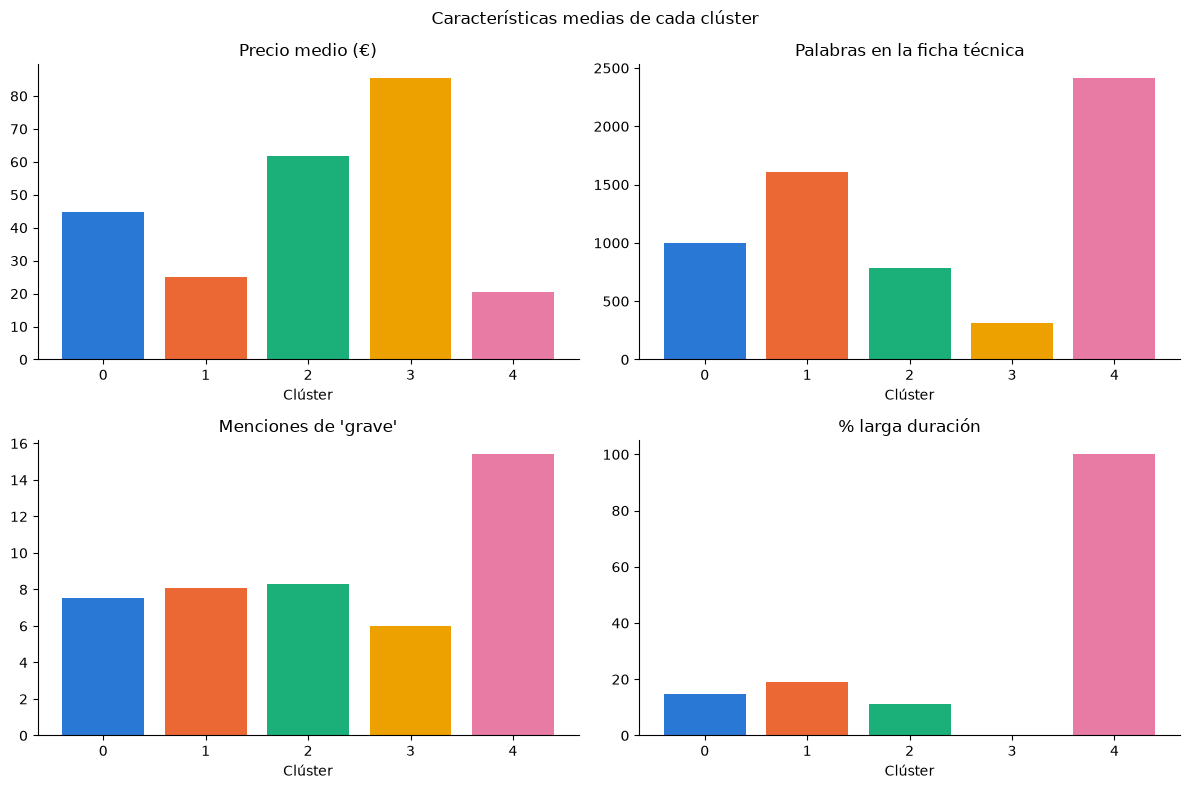

In [26]:
variables = {
    "Precio venta al público con IVA": "Precio medio (€)",
    "Volumen Informativo de Seguridad (num palabras)": "Palabras en la ficha técnica",
    "Indicador de Riesgo Severo (num veces grave/s)": "Menciones de 'grave'",
    "Tratamiento de larga duración": "% larga duración",
}

medias = X_con_cluster.groupby("cluster")[list(variables)].mean()
medias["Tratamiento de larga duración"] *= 100  #pasamos de 0-1 a porcentaje

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (col, titulo) in zip(axes.ravel(), variables.items()):
    ax.bar(medias.index.astype(str), medias[col], color=[colores[c] for c in medias.index])
    ax.set_title(titulo)
    ax.set_xlabel("Clúster")
fig.suptitle("Características medias de cada clúster")
plt.tight_layout()
plt.show()

CONCLUSIONES DEL MODELO

QUÉ HEMOS HECHO
Partimos del CSV limpio de la HU4 (583 medicamentos). Usamos todas las columnas numéricas (25 tras pasar "Tratamiento de larga duración" a 1/0 y "Estado" a dummies), las escalamos con StandardScaler y aplicamos K-Means con k = 5.

ELECCIÓN DE k
El método del codo no mostró un codo claro: la inercia baja de forma bastante regular al aumentar k. Elegimos k = 5 porque da grupos que se pueden interpretar.

PERFILES OBTENIDOS
El modelo ha separado los medicamentos en 3 perfiles principales y 2 grupos especiales:

- Comercializados de uso estándar (367, 63 %): el grupo más grande. Todos comercializados y de alta, casi ninguno de larga duración, fichas técnicas más cortas y precio medio de 55,5 €. Predominan pregabalina, lacosamida y levetiracetam.
- Larga duración, económicos y con más avisos de riesgo (116, 20 %): la mayoría son de larga duración (68 %), con el precio medio más bajo y las fichas más extensas y con más menciones de "grave" de los grupos grandes. Predominan lamotrigina, zonisamida y gabapentina.
- No comercializados / dados de baja (95, 16 %): ninguno está comercializado ni de alta. El modelo los ha agrupado sobre todo por su estado administrativo.
- Especial: valproico de liberación prolongada (2): los únicos con comprimido de liberación modificada.
- Especial: midazolam vía bucal (3): los BUCCOLAM, únicos por vía bucal y con el precio medio más alto (85 €).

LIMITACIONES
- No hay un número de grupos "natural" en los datos: k = 5 es una elección para poder interpretar los grupos, no un óptimo.
- Al incluir todas las columnas, las que casi no varían (formas farmacéuticas o vías que solo tienen 1–3 medicamentos) hacen que K-Means dedique clústeres enteros a muy pocos medicamentos (los dos grupos especiales).
- El gráfico PCA en 2D solo recoge el 26 % de la información, así que es una vista aproximada de los grupos.
- En los datos de origen hay 14 medicamentos marcados como comercializados pero con estado "BAJA POR NO COMERCIALIZAR" (en el perfil de larga duración).

RESULTADO
Guardamos el fichero medicamentos_epilepsia_HU5_clusters.csv, con los datos limpios de la HU4 y las columna nueva "perfil".